In [1]:
import pandas as pd

delay_dataset = pd.read_csv("TTC_Bus_Delays_Cleaned_2021_2026.csv")

print(delay_dataset.head(5))

         Date Route   Time     Day              Location            Incident  \
0  2021-01-01   320  04:26  Friday     Yonge And Steeles  Emergency Services   
1  2021-01-01    63  05:04  Friday  Canniff And Strachan          Mechanical   
2  2021-01-01    42  05:34  Friday         Wilson Garage          Mechanical   
3  2021-01-01   320  05:44  Friday     Yonge And Steeles  Emergency Services   
4  2021-01-01    35  06:21  Friday          Jane Station              Vision   

   Min Delay  Min Gap Direction  Vehicle  Year  
0          0        0         N     1553  2021  
1         10        0         N     8144  2021  
2         24       48         N     8365  2021  
3         15       30         N     8181  2021  
4         30       60         E     3186  2021  


# **1. Outlier Detection**

In [2]:
# Descriptive statistics
print("Descriptive Statistics:")
display(delay_dataset[['Min Delay', 'Min Gap']].describe())

# Check negative and zero values
for col in ['Min Delay', 'Min Gap']:

    print(f"\n{col}:")

    print("Negative values:",
          (delay_dataset[col] < 0).sum())

    print("Zero values:",
          (delay_dataset[col] == 0).sum())

    # Calculate IQR
    Q1 = delay_dataset[col].quantile(0.25)
    Q3 = delay_dataset[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Count outliers
    outliers = (
        (delay_dataset[col] < lower_bound) |
        (delay_dataset[col] > upper_bound)
    ).sum()

    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Potential Outliers:", outliers)

# Display largest delays
print("\nTop 10 Largest Delays:")
print(delay_dataset.nlargest(10, 'Min Delay')[
        ['Year', 'Date', 'Route', 'Incident',
         'Min Delay', 'Min Gap']
    ]
)

Descriptive Statistics:


,Min Delay,Min Gap
count,317758.000000,317758.000000
mean,20.546627,33.003156
std,50.834748,52.664143
min,0.000000,0.000000
25%,8.000000,16.000000
50%,11.000000,22.000000
75%,20.000000,40.000000
max,999.000000,999.000000



Min Delay:
Negative values: 0
Zero values: 29327
Lower Bound: -10.0
Upper Bound: 38.0
Potential Outliers: 16876

Min Gap:
Negative values: 0
Zero values: 30406
Lower Bound: -20.0
Upper Bound: 76.0
Potential Outliers: 13237

Top 10 Largest Delays:
        Year        Date    Route       Incident  Min Delay  Min Gap
9080    2021  2021-03-22      162  General Delay        999      999
18980   2021  2021-05-27       34  General Delay        999      999
45806   2022  2022-01-19       96      Diversion        999      101
68242   2022  2022-06-24       32      Diversion        999      999
71452   2022  2022-07-14  Unknown      Diversion        999      999
87780   2022  2022-10-08      121      Diversion        999      100
232754  2025  2025-04-18       12      Diversion        999      101
131385  2023  2023-08-09      121      Diversion        998      101
28132   2021  2021-09-14       36      Diversion        997      100
107542  2023  2023-02-23       77      Diversion        997   

In [3]:
print("Min Delay values >= 360:")
print((delay_dataset['Min Delay'] > 360).sum())

print(
    delay_dataset[delay_dataset['Min Delay'] >= 360][['Year', 'Date', 'Route', 'Incident', 'Min Delay', 'Min Gap']
    ].sort_values('Min Delay', ascending=False).head(15)
)

Min Delay values >= 360:
1740
        Year        Date    Route       Incident  Min Delay  Min Gap
45806   2022  2022-01-19       96      Diversion        999      101
232754  2025  2025-04-18       12      Diversion        999      101
9080    2021  2021-03-22      162  General Delay        999      999
68242   2022  2022-06-24       32      Diversion        999      999
18980   2021  2021-05-27       34  General Delay        999      999
71452   2022  2022-07-14  Unknown      Diversion        999      999
87780   2022  2022-10-08      121      Diversion        999      100
131385  2023  2023-08-09      121      Diversion        998      101
28132   2021  2021-09-14       36      Diversion        997      100
306856  2026  2026-06-16       11      Diversion        997      101
230449  2025  2025-04-03       57      Diversion        997      101
107542  2023  2023-02-23       77      Diversion        997      105
121108  2023  2023-06-05       75      Diversion        997      101
2946

In [4]:
# Second Dataset: Exclude delays > 360 minutes
filtered_dataset = delay_dataset[delay_dataset['Min Delay'] <= 360].copy()

print("Original dataset:", delay_dataset.shape)
print("Filtered dataset:", filtered_dataset.shape)
print("Removed rows:", len(delay_dataset) - len(filtered_dataset))

# Save both datasets as CSV
delay_dataset.to_csv('TTC_Bus_Delays_2021_2026_with_outliers.csv', index=False)
filtered_dataset.to_csv('TTC_Bus_Delays_2021_2026_without_outliers.csv', index=False)

print("\nDatasets exported successfully!")

print("Final Shape for Original Dataset:", delay_dataset.shape)
print("Final Shape for Filtered Dataset:", filtered_dataset.shape)

Original dataset: (317758, 11)
Filtered dataset: (316018, 11)
Removed rows: 1740

Datasets exported successfully!
Final Shape for Original Dataset: (317758, 11)
Final Shape for Filtered Dataset: (316018, 11)


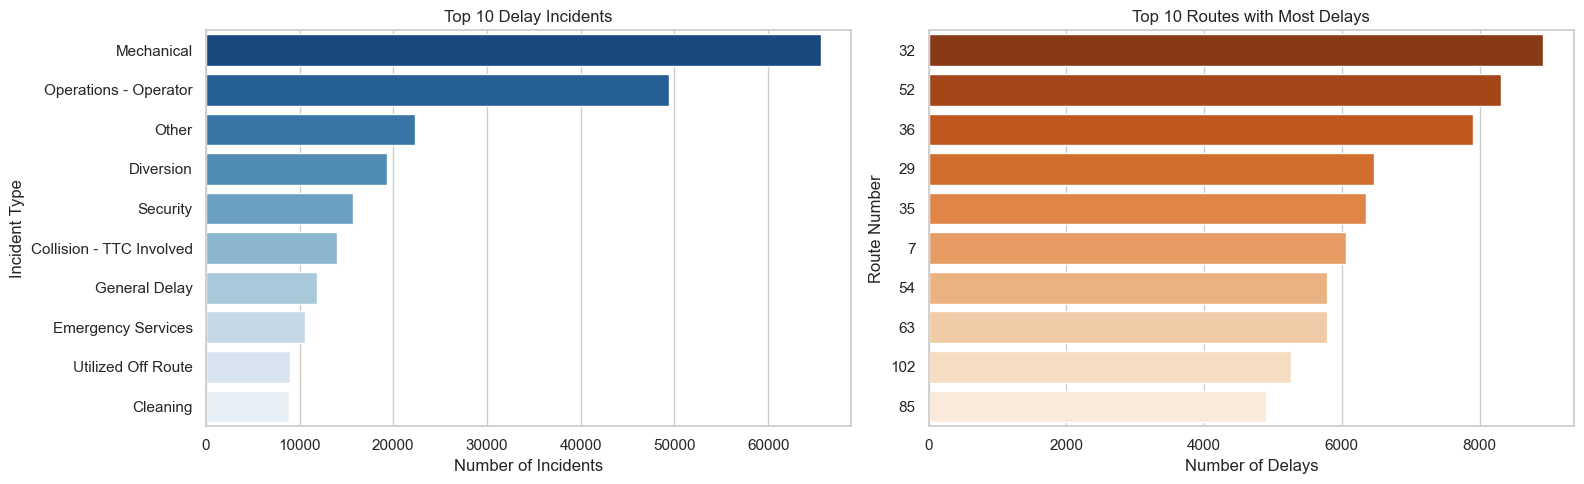

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

delay_dataset = pd.read_csv("TTC_Bus_Delays_Cleaned_2021_2026.csv")

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

top_incidents = delay_dataset["Incident"].value_counts().head(10)

sns.barplot(
ax=axes[0],
x=top_incidents.values,
y=top_incidents.index,
hue=top_incidents.index,
palette="Blues_r",
legend=False
)

axes[0].set_title("Top 10 Delay Incidents")
axes[0].set_xlabel("Number of Incidents")
axes[0].set_ylabel("Incident Type")

top_routes = delay_dataset["Route"].value_counts().head(10)

sns.barplot(
ax=axes[1],
x=top_routes.values,
y=top_routes.index.astype(str),
hue=top_routes.index.astype(str),
palette="Oranges_r",
legend=False
)

axes[1].set_title("Top 10 Routes with Most Delays")
axes[1].set_xlabel("Number of Delays")
axes[1].set_ylabel("Route Number")

plt.tight_layout()
plt.show()

In [6]:
from scipy.stats import pearsonr, spearmanr

# Select the two variables and remove missing/infinite values
data = delay_dataset[['Min Delay', 'Min Gap']].copy()
data = data.replace([float('inf'), float('-inf')], float('nan')).dropna()

# Calculate correlations
pearson_r, pearson_p = pearsonr(data['Min Delay'], data['Min Gap'])
spearman_r, spearman_p = spearmanr(data['Min Delay'], data['Min Gap'])

print(f"Number of records: {len(data)}")
print(f"Pearson correlation:  {pearson_r:.4f}, p-value: {pearson_p:.6g}")
print(f"Spearman correlation: {spearman_r:.4f}, p-value: {spearman_p:.6g}")


Number of records: 317758
Pearson correlation:  0.9615, p-value: 0
Spearman correlation: 0.9604, p-value: 0


In [7]:
route_data = delay_dataset[
    ['Route', 'Min Delay', 'Min Gap']
].copy()

route_data = route_data.dropna(
    subset=['Route', 'Min Delay', 'Min Gap']
)

results = []

for route, group in route_data.groupby('Route'):
    # Require enough records for a meaningful comparison
    if len(group) < 30:
        continue

    # Correlation is undefined if either variable is constant
    if (group['Min Delay'].nunique() < 2 or
            group['Min Gap'].nunique() < 2):
        continue

    r, p = pearsonr(group['Min Delay'], group['Min Gap'])
    rho, p_s = spearmanr(group['Min Delay'], group['Min Gap'])

    results.append({
        'Route': route,
        'Records': len(group),
        'Pearson_r': r,
        'Pearson_p': p,
        'Spearman_rho': rho,
        'Spearman_p': p_s
    })

route_correlations = pd.DataFrame(results)

route_correlations = route_correlations.sort_values(
    'Records', ascending=False
)

print(route_correlations.to_string(index=False))


  Route  Records  Pearson_r     Pearson_p  Spearman_rho    Spearman_p
     32     8924   0.971641  0.000000e+00      0.953915  0.000000e+00
     52     8313   0.951994  0.000000e+00      0.930365  0.000000e+00
     36     7904   0.961059  0.000000e+00      0.940022  0.000000e+00
     29     6471   0.988147  0.000000e+00      0.969069  0.000000e+00
     35     6357   0.989855  0.000000e+00      0.952639  0.000000e+00
      7     6065   0.971088  0.000000e+00      0.927418  0.000000e+00
     54     5784   0.960485  0.000000e+00      0.955120  0.000000e+00
     63     5782   0.987527  0.000000e+00      0.951062  0.000000e+00
    102     5263   0.897101  0.000000e+00      0.941774  0.000000e+00
     85     4905   0.967494  0.000000e+00      0.952797  0.000000e+00
     95     4811   0.968133  0.000000e+00      0.956162  0.000000e+00
     96     4755   0.943471  0.000000e+00      0.949382  0.000000e+00
     34     4691   0.982398  0.000000e+00      0.962290  0.000000e+00
    939     4623   0

In [8]:
incident_data = delay_dataset[
    ['Incident', 'Min Delay', 'Min Gap']
].dropna()

results = []

for incident, group in incident_data.groupby('Incident'):
    if len(group) < 30:
        continue

    if (group['Min Delay'].nunique() < 2 or
            group['Min Gap'].nunique() < 2):
        continue

    r, p = pearsonr(group['Min Delay'], group['Min Gap'])
    rho, p_s = spearmanr(group['Min Delay'], group['Min Gap'])

    results.append({
        'Incident': incident,
        'Records': len(group),
        'Pearson_r': r,
        'Pearson_p': p,
        'Spearman_rho': rho,
        'Spearman_p': p_s
    })

incident_correlations = pd.DataFrame(results)

if not incident_correlations.empty:
    print(
        incident_correlations
        .sort_values('Records', ascending=False)
        .to_string(index=False)
    )
else:
    print("No incident types have enough usable records.")


                                     Incident  Records  Pearson_r     Pearson_p  Spearman_rho    Spearman_p
                                   Mechanical    65589   0.873422  0.000000e+00      0.964384  0.000000e+00
                        Operations - Operator    49430   0.805449  0.000000e+00      0.941702  0.000000e+00
                                        Other    22277   0.876224  0.000000e+00      0.956767  0.000000e+00
                                    Diversion    19364   0.969434  0.000000e+00      0.960946  0.000000e+00
                                     Security    15706   0.833638  0.000000e+00      0.979220  0.000000e+00
                     Collision - TTC Involved    13992   0.917617  0.000000e+00      0.980922  0.000000e+00
                                General Delay    11862   0.934366  0.000000e+00      0.904593  0.000000e+00
                           Emergency Services    10534   0.871565  0.000000e+00      0.978337  0.000000e+00
                           U

In [9]:
data = delay_dataset[['Min Delay', 'Min Gap']].dropna().copy()

# Original data
original_pearson = pearsonr(data['Min Delay'], data['Min Gap'])[0]
original_spearman = spearmanr(data['Min Delay'], data['Min Gap'])[0]

# Sensitivity check: exclude the highest 1% of delay values
delay_99 = data['Min Delay'].quantile(0.99)
filtered = data[data['Min Delay'] <= delay_99]

filtered_pearson = pearsonr(
    filtered['Min Delay'], filtered['Min Gap']
)[0]
filtered_spearman = spearmanr(
    filtered['Min Delay'], filtered['Min Gap']
)[0]

print(f"Original records: {len(data)}")
print(f"Records after sensitivity check: {len(filtered)}")
print(f"99th percentile delay threshold: {delay_99:.2f} minutes")
print()
print(f"Original Pearson: {original_pearson:.4f}")
print(f"Filtered Pearson: {filtered_pearson:.4f}")
print(f"Original Spearman: {original_spearman:.4f}")
print(f"Filtered Spearman: {filtered_spearman:.4f}")


Original records: 317758
Records after sensitivity check: 314580
99th percentile delay threshold: 230.43 minutes

Original Pearson: 0.9615
Filtered Pearson: 0.9051
Original Spearman: 0.9604
Filtered Spearman: 0.9593
